## Task 2: Restaurant Recommendation

In [13]:
import pandas as pd
import numpy as np

df = pd.read_csv("Dataset .csv")

print("Dataset loaded successfully.")
print("Dataset Shape:", df.shape)

Dataset loaded successfully.
Dataset Shape: (9551, 21)


##### 2. Dataset Inspection

In [14]:
print("Column Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nFirst 5 Rows:")
display(df.head())

Column Names:
['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address', 'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines', 'Average Cost for two', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu', 'Price range', 'Aggregate rating', 'Rating color', 'Rating text', 'Votes']

Missing Values:
Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                9
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64

Duplicate Rows: 0

First 5 Rows:


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


##### 3. Data Preprocessing

In [15]:
# Create a copy for the recommendation system
recommendation_df = df[
    [
        "Restaurant ID",
        "Restaurant Name",
        "Cuisines",
        "Price range",
        "City",
        "Aggregate rating",
        "Votes"
    ]
].copy()

print("Missing values before preprocessing:")
print(recommendation_df.isnull().sum())

# Handle missing values
recommendation_df["Cuisines"] = recommendation_df["Cuisines"].fillna("Unknown")

recommendation_df["Price range"] = recommendation_df["Price range"].fillna(
    recommendation_df["Price range"].mode()[0]
)

recommendation_df["Restaurant Name"] = recommendation_df["Restaurant Name"].fillna(
    "Unknown Restaurant"
)

recommendation_df["City"] = recommendation_df["City"].fillna("Unknown")

print("\nMissing values after preprocessing:")
print(recommendation_df.isnull().sum())

Missing values before preprocessing:
Restaurant ID       0
Restaurant Name     0
Cuisines            9
Price range         0
City                0
Aggregate rating    0
Votes               0
dtype: int64

Missing values after preprocessing:
Restaurant ID       0
Restaurant Name     0
Cuisines            0
Price range         0
City                0
Aggregate rating    0
Votes               0
dtype: int64


##### 4. Remove Duplicate Restaurant Records

In [16]:
print("Duplicate records before removal:", recommendation_df.duplicated().sum())

recommendation_df = recommendation_df.drop_duplicates(
    subset=["Restaurant ID"]
).reset_index(drop=True)

print("Duplicate records after removal:", recommendation_df.duplicated().sum())

print("Recommendation dataset shape:", recommendation_df.shape)

Duplicate records before removal: 0
Duplicate records after removal: 0
Recommendation dataset shape: (9551, 7)


##### 5. Recommendation Criteria

The recommendation system uses two main user preference criteria:

1. Cuisine preference
2. Price range

In [18]:
# User preference criteria
preferred_cuisine = "North Indian"
preferred_price_range = 2

print("User Preferences")
print("Preferred Cuisine:", preferred_cuisine)
print("Preferred Price Range:", preferred_price_range)

User Preferences
Preferred Cuisine: North Indian
Preferred Price Range: 2


##### 6. Encode Categorical Variables

In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder

# Convert cuisine information into TF-IDF features
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english"
)

cuisine_features = tfidf.fit_transform(
    recommendation_df["Cuisines"].astype(str)
)

# Encode price range
price_encoder = OneHotEncoder(
    handle_unknown="ignore"
)

price_features = price_encoder.fit_transform(
    recommendation_df[["Price range"]]
)

print("Cuisine feature shape:", cuisine_features.shape)
print("Price feature shape:", price_features.shape)

Cuisine feature shape: (9551, 149)
Price feature shape: (9551, 4)


##### 7. Create Content-Based Feature Matrix

In [20]:
from scipy.sparse import hstack

# Combine cuisine and price-range features
content_features = hstack([
    cuisine_features,
    price_features
])

print("Content-based feature matrix shape:", content_features.shape)

Content-based feature matrix shape: (9551, 153)


##### 8. Content-Based Recommendation System

In [21]:

from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import hstack

def recommend_restaurants(
    preferred_cuisine,
    preferred_price_range,
    top_n=10
):
    # Transform the user's cuisine preference
    user_cuisine = tfidf.transform([preferred_cuisine])

    # Transform the user's price range
    user_price = price_encoder.transform(
        [[preferred_price_range]]
    )

    # Combine the user's preference features
    user_features = hstack([
        user_cuisine,
        user_price
    ])

    # Calculate similarity scores
    similarity_scores = cosine_similarity(
        user_features,
        content_features
    ).flatten()

    # Create the result dataframe
    results = recommendation_df.copy()
    results["Similarity Score"] = similarity_scores

    # Sort by similarity and then restaurant rating
    results = results.sort_values(
        by=["Similarity Score", "Aggregate rating"],
        ascending=[False, False]
    )

    return results.head(top_n)


In [22]:
print("recommend_restaurants:", "recommend_restaurants" in globals())
print("tfidf:", "tfidf" in globals())
print("price_encoder:", "price_encoder" in globals())
print("content_features:", "content_features" in globals())
print("recommendation_df:", "recommendation_df" in globals())

recommend_restaurants: True
tfidf: True
price_encoder: True
content_features: True
recommendation_df: True


##### 9. Test the Recommendation System

In [23]:

# Sample user preferences
preferred_cuisine = "North Indian"
preferred_price_range = 2

# Check whether the required variables exist
if all(name in globals() for name in [
    "tfidf",
    "price_encoder",
    "content_features",
    "recommendation_df"
]):
    recommendations = recommend_restaurants(
        preferred_cuisine,
        preferred_price_range,
        top_n=10
    )

    display(
        recommendations[
            [
                "Restaurant Name",
                "Cuisines",
                "Price range",
                "City",
                "Aggregate rating",
                "Similarity Score"
            ]
        ]
    )
else:
    print("Required setup variables are missing. Run the previous setup cells first.")


c:\Users\rupes\Anaconda\Lib\site-packages\sklearn\base.py:464: UserWarning: X does not have valid feature names, but OneHotEncoder was fitted with feature names
  warnings.warn(


,Restaurant Name,Cuisines,Price range,City,Aggregate rating,Similarity Score
2114,Tandoor Express,North Indian,2,Gurgaon,4.2,1.0
702,Kesar Da Dhabha,North Indian,2,Amritsar,4.1,1.0
2360,Gyan Vaishnav,North Indian,2,Kanpur,3.9,1.0
8084,Mirchievous,North Indian,2,Noida,3.9,1.0
699,Brothers Dhaba,North Indian,2,Amritsar,3.8,1.0
700,Brothers' Amritsari Dhaba,North Indian,2,Amritsar,3.8,1.0
703,Beera Chicken Corner,North Indian,2,Amritsar,3.8,1.0
795,Pal Dhaba,North Indian,2,Chandigarh,3.8,1.0
1392,Veg Ex,North Indian,2,Gurgaon,3.8,1.0
6758,Satvik Rasoi,North Indian,2,New Delhi,3.8,1.0


##### 10. Recommendation Quality Evaluation

In [24]:
# Check cuisine preference match
recommendations["Cuisine Match"] = recommendations["Cuisines"].str.contains(
    preferred_cuisine,
    case=False,
    na=False
)

# Check price range match
recommendations["Price Match"] = (
    recommendations["Price range"] == preferred_price_range
)

# Calculate matching percentages
cuisine_match_rate = recommendations["Cuisine Match"].mean() * 100
price_match_rate = recommendations["Price Match"].mean() * 100
overall_match_rate = (
    recommendations["Cuisine Match"] &
    recommendations["Price Match"]
).mean() * 100

print("Recommendation Quality Evaluation")
print("----------------------------------")
print(f"Cuisine Match Rate: {cuisine_match_rate:.2f}%")
print(f"Price Range Match Rate: {price_match_rate:.2f}%")
print(f"Overall Preference Match Rate: {overall_match_rate:.2f}%")

Recommendation Quality Evaluation
----------------------------------
Cuisine Match Rate: 100.00%
Price Range Match Rate: 100.00%
Overall Preference Match Rate: 100.00%


##### 11. Recommendation Similarity Visualization


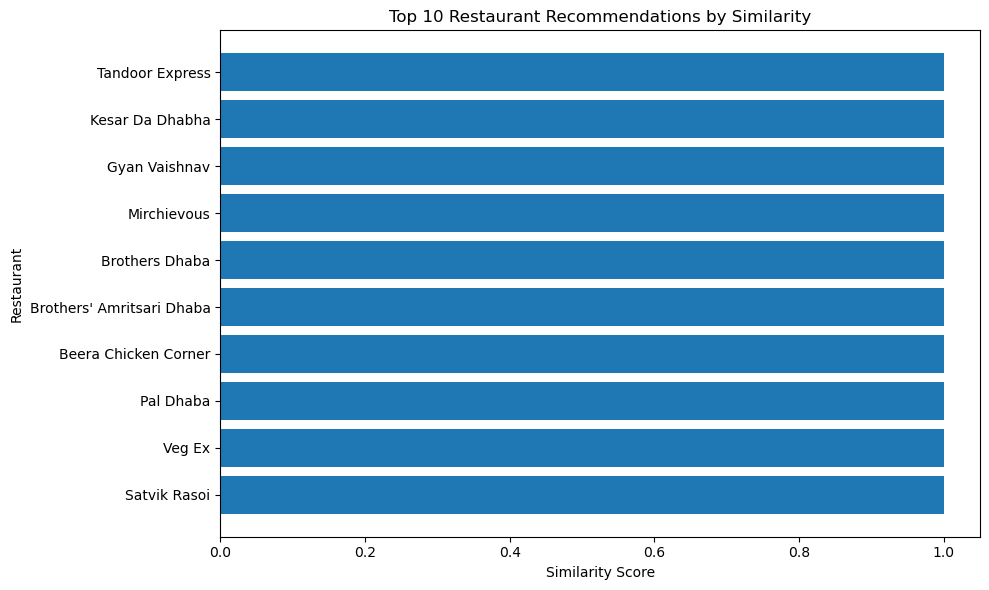

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    recommendations["Restaurant Name"].astype(str),
    recommendations["Similarity Score"]
)

plt.xlabel("Similarity Score")
plt.ylabel("Restaurant")
plt.title("Top 10 Restaurant Recommendations by Similarity")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

##### 12. Price Range of Recommended Restaurants

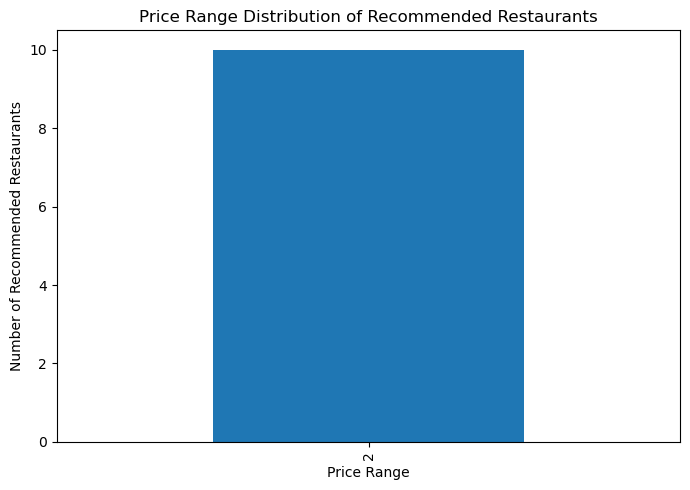

In [27]:
plt.figure(figsize=(7, 5))

recommendations["Price range"].value_counts().sort_index().plot(
    kind="bar"
)

plt.xlabel("Price Range")
plt.ylabel("Number of Recommended Restaurants")
plt.title("Price Range Distribution of Recommended Restaurants")

plt.tight_layout()
plt.show()

##### 13. Final Recommendations

In [28]:
final_recommendations = recommendations[
    [
        "Restaurant Name",
        "Cuisines",
        "Price range",
        "City",
        "Aggregate rating",
        "Similarity Score"
    ]
].copy()

final_recommendations.index = range(1, len(final_recommendations) + 1)

display(final_recommendations)

,Restaurant Name,Cuisines,Price range,City,Aggregate rating,Similarity Score
1,Tandoor Express,North Indian,2,Gurgaon,4.2,1.0
2,Kesar Da Dhabha,North Indian,2,Amritsar,4.1,1.0
3,Gyan Vaishnav,North Indian,2,Kanpur,3.9,1.0
4,Mirchievous,North Indian,2,Noida,3.9,1.0
5,Brothers Dhaba,North Indian,2,Amritsar,3.8,1.0
6,Brothers' Amritsari Dhaba,North Indian,2,Amritsar,3.8,1.0
7,Beera Chicken Corner,North Indian,2,Amritsar,3.8,1.0
8,Pal Dhaba,North Indian,2,Chandigarh,3.8,1.0
9,Veg Ex,North Indian,2,Gurgaon,3.8,1.0
10,Satvik Rasoi,North Indian,2,New Delhi,3.8,1.0


#### 14. Conclusion

A content-based restaurant recommendation system was developed based on user preferences.

The dataset was preprocessed by handling missing values and removing duplicate restaurant records. Cuisine information was represented using TF-IDF, while price range was encoded using One-Hot Encoding.

Cuisine preference and price range were selected as the main recommendation criteria. Cosine similarity was then used to compare the user's preferences with restaurant feature representations and generate ranked recommendations.

The system was tested using sample preferences for North Indian cuisine and a price range of 2. The recommendation quality was evaluated by measuring cuisine and price-range preference matching.

The recommendation results and similarity scores were also visualized to make the output easier to interpret.